In [ ]:
import torch
from torch import optim
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.preprocessing import OneHotEncoder
!mkdir /content/models

mkdir: cannot create directory ‘/content/models’: File exists


In [ ]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.preprocessing import OneHotEncoder

# 1. 입력 특성 3개(X), 클래스 3개(y) 데이터셋 생성
X, y_integer = make_classification(
    n_samples=1000,           # 전체 데이터 샘플 개수
    n_features=3,            # 입력 특성(X) 개수 = 3개
    n_informative=3,         # 예측에 유용한 특성 개수 = 3개 (2^3 = 8 >= 3*1)
    n_redundant=0,           # 불필요한 중복 특성 개수
    n_classes=3,             # 출력 클래스 개수 = 3개 (0, 1, 2)
    n_clusters_per_class=1,  # 클래스당 덩어리 수 = 1개
    class_sep=1.5,           # 클래스 간 분리 정도
    random_state=42
)

# 2. 소프트맥스(Softmax)용 원-핫 인코딩 변환 [0, 1, 2] -> [[1,0,0], [0,1,0], [0,0,1]]
encoder = OneHotEncoder(sparse_output=False)
y_onehot = encoder.fit_transform(y_integer.reshape(-1, 1))

# 3. 데이터 크기 및 결과 확인
print("X 크기 (Shape):", X.shape)         # (300, 3) -> 샘플 300개, 특성 3개
print("y 크기 (Shape):", y_onehot.shape)  # (300, 3) -> 샘플 300개, 클래스 3개

print("\nX 상위 3개 데이터:\n", X[:3])
print("\ny (원-핫 인코딩) 상위 3개 데이터:\n", y_onehot[:3])

df = np.hstack((X, y_onehot))
df = pd.DataFrame(df)
df.head()
len(df)
df.size

X 크기 (Shape): (1000, 3)
y 크기 (Shape): (1000, 3)

X 상위 3개 데이터:
 [[-1.09032049 -2.8939713  -2.28763838]
 [-2.41349161 -1.89218986 -1.33254143]
 [-1.88847955  1.94735632  1.85848562]]

y (원-핫 인코딩) 상위 3개 데이터:
 [[0. 0. 1.]
 [0. 0. 1.]
 [0. 1. 0.]]


6000

In [ ]:
class MyDataset1(Dataset):
  def __init__(self, df):
    self.df = df
    self.x = self.df.iloc[:,0:3].values
    self.y = self.df.iloc[:,3:6].values
    self.length = len(df)

  def __getitem__(self, index):
    x = torch.FloatTensor([self.x[index]])
    y = torch.FloatTensor([self.y[index]])
    return x, y

  def __len__(self):
    return self.length

class MyModel1(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer = nn.Sequential(
        nn.Linear(3,3),
        nn.Sigmoid()
    )

  def forward(self, x):
    x = self.layer(x)
    return x

D = MyDataset1(df)
len(D)

1000

epoch: 10, loss: 0.03
epoch: 20, loss: 0.02
epoch: 30, loss: 0.02
epoch: 40, loss: 0.02
epoch: 50, loss: 0.02
epoch: 60, loss: 0.02
epoch: 70, loss: 0.02
epoch: 80, loss: 0.02
epoch: 90, loss: 0.02
epoch: 100, loss: 0.01
epoch: 110, loss: 0.01
epoch: 120, loss: 0.01
epoch: 130, loss: 0.01
epoch: 140, loss: 0.01
epoch: 150, loss: 0.01
epoch: 160, loss: 0.01
epoch: 170, loss: 0.01
epoch: 180, loss: 0.01
epoch: 190, loss: 0.01
epoch: 200, loss: 0.01
Training Complete
평가점수: 0.01


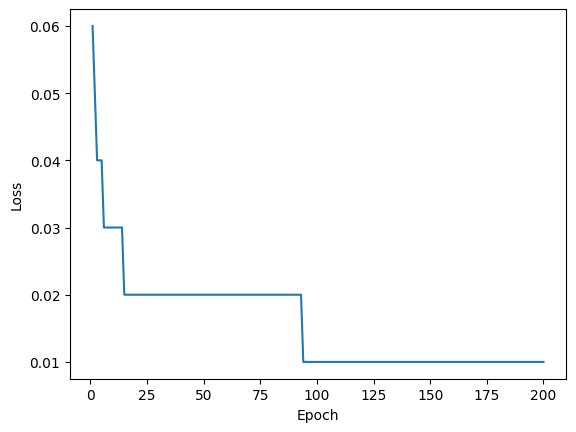

In [ ]:
# Trainer
device = 'cuda' if torch.cuda.is_available() else 'cpu'
dataset = MyDataset1(df)
train_size = 800
eval_size = 200
batch_size = 10
train_dataset, eval_dataset = random_split(dataset, [train_size, eval_size])
train_dataloader = DataLoader(train_dataset, batch_size = batch_size,
                                 shuffle = True,
                                 drop_last = True)
eval_dataloader = DataLoader(eval_dataset, batch_size = batch_size,
                             shuffle = True,
                             drop_last = True)

learning_rate = 0.01
epoch = 200

model = MyModel1().to(device)
criterion = nn.BCELoss().to(device)
optimizer = optim.SGD(model.parameters(), lr = learning_rate)


epoch_memory = [x+1 for x in range(200)]
loss_memory = []
checkpoint = 0

for epoch in range(epoch):
  cost = torch.FloatTensor([0.0])
  for x, y in train_dataloader:
    x = x.to(device)
    y = y.to(device)
    output = model(x)

    loss = criterion(output, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    cost += loss

  loss_memory.append(round(cost.item() / len(train_dataset), 2))
  checkpoint += 1

  if (epoch+1) % 10 == 0:
      print(f"epoch: {epoch+1}, loss: {(cost.item() / len(train_dataset)):.2f}")

  if (epoch+1) % 100 == 0:
    torch.save({"model" : "MyModel",
                "epoch" : epoch,
              "model_state_dict":model.state_dict(),
              "optimizer_state_dict":optimizer.state_dict(),
              "cost":cost,
              "description":f"MyModel Checkpoint {checkpoint}"
              }, f"models/checkpoint-{checkpoint}.pt")

plt.plot(epoch_memory, loss_memory)
plt.xlabel('Epoch')
plt.ylabel('Loss')

torch.save(model, "models/model.pt")
torch.save(model.state_dict(), "models/model_state_dict.pt")
print('Training Complete')

# evaluation
model = torch.load('models/model.pt', map_location = device, weights_only = False)
model.eval()

with torch.no_grad():
  cost = torch.FloatTensor([0.0])
  for x, y in eval_dataloader:
    x = x.to(device)
    y = y.to(device)
    output = model(x)
    loss = criterion(output, y)
    cost += loss.item()


model = torch.load('models/model.pt', map_location = device, weights_only = False)
cost = round(cost.item() / len(eval_dataset), 2)
print('평가점수:', cost)

# inference
def model_infer(x):
  model = torch.load('models/model.pt', map_location = device, weights_only = False)
  model.eval()

  output = model(x)
  output = nn.Softmax(x)

  return output

In [ ]:
X = torch.from_numpy(X).float()

print(X)
X = X[:5]
print(X)


print(model(X))

tensor([[-1.0903, -2.8940, -2.2876],
        [-2.4135, -1.8922, -1.3325],
        [-1.8885,  1.9474,  1.8585],
        ...,
        [-1.3882,  1.4798, -1.9987],
        [-1.7873, -2.8853, -1.8764],
        [-1.7542,  0.9795,  0.6652]])
tensor([[-1.0903, -2.8940, -2.2876],
        [-2.4135, -1.8922, -1.3325],
        [-1.8885,  1.9474,  1.8585],
        [-1.7938,  1.5124, -0.4192],
        [-1.0474,  0.3258, -1.7981]])
tensor([[4.1883e-03, 3.6054e-04, 9.9939e-01],
        [2.2181e-03, 3.6552e-03, 9.9672e-01],
        [7.1706e-02, 9.9194e-01, 1.0383e-02],
        [6.8994e-01, 1.2147e-01, 2.8350e-02],
        [7.8149e-01, 2.7582e-03, 2.7261e-01]], grad_fn=<SigmoidBackward0>)
